In [18]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langgraph.graph import START, END
from langgraph.graph.state import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
import os
from dotenv import load_dotenv
load_dotenv()

True

In [19]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="qwen/qwen3.8-27b")
llm


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000157B1081810>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000157B1083B10>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [27]:
import os
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["LANGGCHAIN_API_KEY"]=os.getenv("LANGGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"
os.environ["LANGCHAIN_PROJECT"]="Langhsmith"
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"

In [21]:
class State(TypedDict):
    messages:Annotated[list[BaseMessage], add_messages]

In [22]:
## Graph with tool call
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool

@tool
def add(a:float, b:float):
    """Add to number"""
    return a+b

tools=[add]
tool_node =ToolNode([add])

llm_with_tool=llm.bind_tools([add])

def call_llm_mode(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}


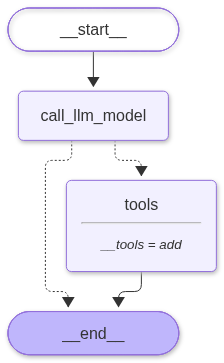

In [23]:
from IPython.display import Image, display
# Node defination
def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

## Gharph
builder=StateGraph(State)
builder.add_node("call_llm_model",call_llm_model)
builder.add_node("tools", ToolNode(tools))

## Add edges
builder.add_edge(START, "call_llm_model")
builder.add_conditional_edges("call_llm_model", tools_condition)
builder.add_edge("tools", END)

#compile the graph
graph=builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
response=graph.invoke({"messages":"What is the Machine learning"})

Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=01a20caa-0b5b-7156-bed3-6b51c1ed832a,id=01a20caa-0b5b-7156-bed3-6b51c1ed832a; trace=01a20caa-0b5b-7156-bed3-6b51c1ed832a,id=01a20caa-0b5d-70c7-9a44-e1577d312a26; trace=01a20caa-0b5b-7156-bed3-6b51c1ed832a,id=01a20caa-0b5e-74a1-816a-8d2486a99ac5
Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=01a20caa-0b5b-7156-bed3-6b51c1ed832a,id=01a20caa-0b5e-74a1-816a-8d2486a99ac5; trace=01a20caa-0b5b-7156-bed3-6b51c1ed832a,id=01a20caa-1020-762e-b23e-5ecd3ccb145e; trace=01a20caa-